# Multiwell Productivity Index → CRM

The multiwell productivity index (MPI, Kaviani and Valkó, 2010) turns well
locations into a producer–injector influence matrix $\Lambda$ on a rectangular,
roughly homogeneous reservoir in semi-steady state.

$\Lambda$ is negative. CRM wants positive gains, so the library uses
$f_{ij}^{(0)} = -\Lambda_{ij}$. That matrix is the right first guess when CRM has
many pair parameters to learn.

This notebook builds $\Lambda$ for a 5-injector / 4-producer pattern, then seeds
Deep-CRM with `initial_guess="geometry"` so training starts from the map instead
of a uniform grid.


In [1]:
from __future__ import annotations

import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pywaterflood import CRM, geometry_crm_gains, translate_locations
from pywaterflood.multiwellproductivity import calc_gains_homogeneous


## Well map

`translate_locations` shifts the lower-left well to the origin and standardizes
columns to `X`, `Y`, `Type` (`"Producer"` or `"Injector"`). Index labels are the
well IDs you will pass as `producer_ids` / `injector_ids` so they line up with
rate-column order.

Rotate the map first if the field axes are not aligned with east–north.


,X,Y,Type
I1,0,4,Injector
I2,4,4,Injector
I3,2,2,Injector
I4,0,0,Injector
I5,4,0,Injector
P1,2,4,Producer
P2,0,2,Producer
P3,4,2,Producer
P4,2,0,Producer


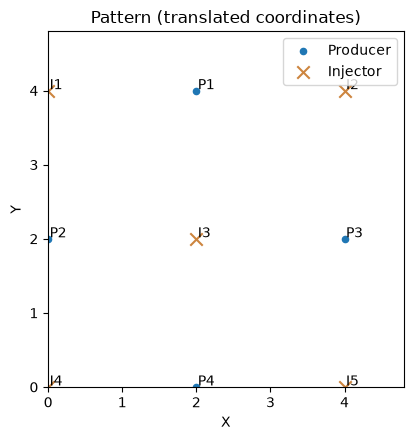

In [2]:
raw = pd.concat(
    [
        pd.DataFrame({"easting": [1, 5, 3, 1, 5], "northing": [5, 5, 3, 1, 1], "kind": "Injector"}),
        pd.DataFrame({"easting": [3, 1, 5, 3], "northing": [5, 3, 3, 1], "kind": "Producer"}),
    ]
)
raw.index = [f"I{i+1}" for i in range(5)] + [f"P{i+1}" for i in range(4)]
locations = translate_locations(raw, "easting", "northing", "kind")
# Rectangle slightly larger than the well bounding box so every well sits inside
x_e = float(locations["X"].max()) * 1.2
y_e = float(locations["Y"].max()) * 1.2

fig, ax = plt.subplots(figsize=(4.5, 4.5))
prod_xy = locations[locations.Type == "Producer"]
inj_xy = locations[locations.Type == "Injector"]
prod_xy.plot.scatter(x="X", y="Y", ax=ax, label="Producer")
inj_xy.plot.scatter(x="X", y="Y", color="peru", marker="x", s=80, ax=ax, label="Injector")
for label, row in locations.iterrows():
    ax.annotate(label, (row.X + 0.02, row.Y + 0.02))
ax.set(xlim=(0, x_e), ylim=(0, y_e), aspect=1, title="Pattern (translated coordinates)")
ax.legend(loc="upper right")
fig.tight_layout()
locations


## Geometric gains

`calc_gains_homogeneous` returns $\Lambda$ (negative). `geometry_crm_gains`
returns $-\Lambda$ as a C-contiguous `(n_producers, n_injectors)` array, reindexed
to the IDs you pass. Those IDs must match production and injection **column order**.


geometry gains shape (4, 5) min 0.13839859302463864 max 0.40272198604761533


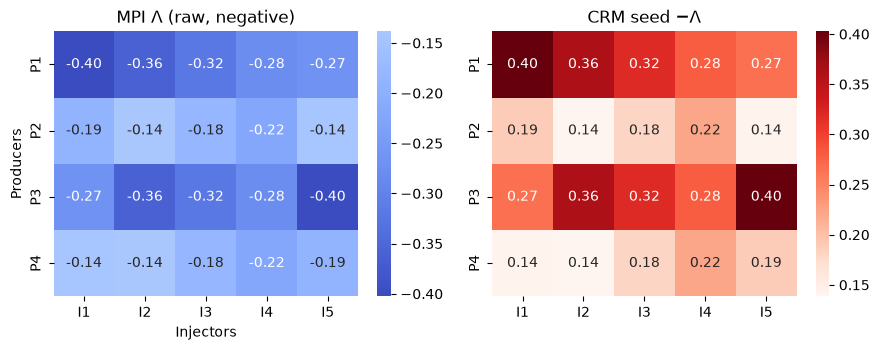

In [3]:
producer_ids = ["P1", "P2", "P3", "P4"]
injector_ids = ["I1", "I2", "I3", "I4", "I5"]

lambda_df = calc_gains_homogeneous(locations, x_e, y_e)
geo = geometry_crm_gains(
    locations,
    x_e,
    y_e,
    producer_ids=producer_ids,
    injector_ids=injector_ids,
)
geo_df = pd.DataFrame(geo, index=producer_ids, columns=injector_ids)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(9, 3.6))
sns.heatmap(lambda_df.loc[producer_ids, injector_ids], ax=ax0, cmap="coolwarm", center=0, annot=True, fmt=".2f")
sns.heatmap(geo_df, ax=ax1, cmap="Reds", annot=True, fmt=".2f")
ax0.set(title=r"MPI $\Lambda$ (raw, negative)")
ax1.set(title=r"CRM seed $-\Lambda$")
fig.tight_layout()
print("geometry gains shape", geo.shape, "min", geo.min(), "max", geo.max())


## Seed CRM from the map

Pass the same locations and IDs into `fit`. Missing `locations` / `x_e` / `y_e`
raises — there is no silent fallback to uniform gains. Connectivity stays
**trainable**; geometry is the start, not a freeze.

The sample rate files have 4 producers and 5 injectors, the same counts as this
pattern. Column 0 of production is treated as P1, and so on.


In [4]:
def load_sample_rates():
    for folder in (Path("../../testing/data"), Path("testing/data")):
        if (folder / "production.csv").exists():
            root = folder
            prod = pd.read_csv(root / "production.csv", header=None)
            inj = pd.read_csv(root / "injection.csv", header=None)
            time = pd.read_csv(root / "time.csv", header=None)
            return prod, inj, time
    gh = "https://raw.githubusercontent.com/frank1010111/pywaterflood/master/testing/data/"
    return (
        pd.read_csv(gh + "production.csv", header=None),
        pd.read_csv(gh + "injection.csv", header=None),
        pd.read_csv(gh + "time.csv", header=None),
    )


prod, inj, time = load_sample_rates()
q, i, t = prod.to_numpy(), inj.to_numpy(), time.to_numpy()[:, 0]
assert q.shape[1] == len(producer_ids)
assert i.shape[1] == len(injector_ids)
n_threads = max(1, min(os.cpu_count() or 1, q.shape[1]))

crm = CRM(primary=True, tau_selection="per-pair", constraints="up-to one")
crm.fit(
    q,
    i,
    t,
    initial_guess="geometry",
    locations=locations,
    x_e=x_e,
    y_e=y_e,
    producer_ids=producer_ids,
    injector_ids=injector_ids,
    epochs=200,
    seed=0,
    num_cores=n_threads,
)
fitted = pd.DataFrame(crm.gains, index=producer_ids, columns=injector_ids)
print("RMSE", float(np.sqrt(np.mean((q - crm.predict()) ** 2))))
fitted.round(3)


/Users/rohit/pywaterflood/python/pywaterflood/crm.py:1347: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  t_obs = torch.as_tensor(time, dtype=_DTYPE, device=device)


RMSE 31.56065890716987


,I1,I2,I3,I4,I5
P1,0.280,0.281,0.239,0.243,0.212
P2,0.277,0.224,0.264,0.258,0.222
P3,0.216,0.271,0.234,0.241,0.283
P4,0.228,0.224,0.263,0.258,0.282


Geometry vs trained CRM: nearby pairs should stay strong. Training is allowed to
move the numbers when the rates disagree with a homogeneous rectangle — that is
the point of history matching.


geometry-seeded RMSE 31.56065890716987
uniform-seeded RMSE  33.48594590633007


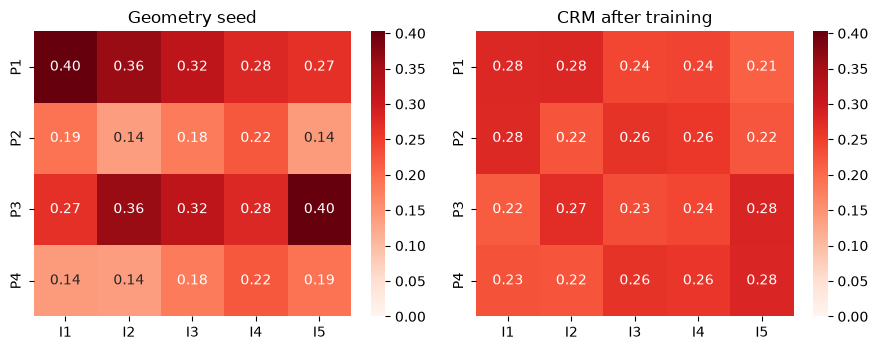

In [5]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(9, 3.6))
sns.heatmap(geo_df, ax=ax0, cmap="Reds", annot=True, fmt=".2f", vmin=0, vmax=max(geo.max(), fitted.to_numpy().max()))
sns.heatmap(fitted, ax=ax1, cmap="Reds", annot=True, fmt=".2f", vmin=0, vmax=max(geo.max(), fitted.to_numpy().max()))
ax0.set(title="Geometry seed")
ax1.set(title="CRM after training")
fig.tight_layout()

# Uniform start on the same data, for contrast
crm_u = CRM(primary=True, tau_selection="per-pair", constraints="up-to one")
crm_u.fit(q, i, t, initial_guess="uniform", epochs=200, seed=0, num_cores=n_threads)
print("geometry-seeded RMSE", float(np.sqrt(np.mean((q - crm.predict()) ** 2))))
print("uniform-seeded RMSE ", float(np.sqrt(np.mean((q - crm_u.predict()) ** 2))))


## Rules that keep well order honest

- `gains[j, i]` is injector $i$ → producer $j$.
- `producer_ids[k]` is production column $k$. If you shuffle IDs, you shuffle the seed.
- MPI assumes a rectangle. Wells must sit inside `(0, x_e) × (0, y_e)` after
  `translate_locations`.
- Use this as a **ranking** on its own when you have no rates yet (well placement).
  After rates arrive, always let CRM train.

On a field with a known aquifer or a strongly heterogeneous thief zone, treat MPI
as a prior, not as the answer.
